# Live text lenses: from prompt to measured readouts

This notebook loads **pretrained GPT-2**, prepares text, runs Logit Lens and Patchscope,
and fits fresh Tuned, Attention and Jacobian lenses. No probe results or figures are read
from `demos/assets`. The four training strings, two validation strings and IOI showcase
are distinct. They are an API demonstration, not enough data for calibrated conclusions.

Install `pip install "vlmprobe[transformers,visualization,notebooks]"` and select that
Python kernel. GPT-2 downloads if absent. Logit Lens works on CPU. Dense Attention
Lens needs roughly 463 million decoder weights for **one layer**; gradients and Adam
increase memory several-fold. Its cell requires explicit opt-in. Exact Jacobian
calibration also requires opt-in because it scales with hidden width.

Every figure below is produced by the displayed library calls. Missing models,
unsupported adapters or missing artifacts raise an error; there is no cached fallback.


## Runtime setup

Run the setup cell first. In Google Colab it obtains a Git checkout and installs
the notebook dependencies; local execution keeps the existing environment.
Choose a GPU runtime when required by the walkthrough.

New Colab checkouts use the reviewed source **gexinh/vlm-probe** at commit
`e2613bf7ef55f1889aa9f95d2004d1ab6770c1b1`. This pins the runtime source for
reproducible execution.

Optional environment settings: VLM_PROBING_REPOSITORY and VLM_PROBING_REF
override that pinned repository and commit; VLM_PROBING_COLAB_DIR changes
the checkout directory (default /content/vlm-probe). The repository and ref
select a new checkout. An existing vlmprobe checkout is reused at its current
commit without discarding local changes. The cell prints that commit.

All input construction, calibration, probing and plotting remain visible in
the analysis cells below. Restart the runtime only if the setup cell reports
that an already imported package or checkout has changed.


In [ ]:
#@title Runtime setup (Colab only; expand to inspect)
# Environment setup only; the analysis workflow is visible in the cells below.
import os as _nb_setup_os
import sys as _nb_setup_sys

_nb_setup_in_colab = (
    "google.colab" in _nb_setup_sys.modules
    or bool(_nb_setup_os.environ.get("COLAB_RELEASE_TAG"))
)
if _nb_setup_in_colab:
    import hashlib as _nb_setup_hashlib
    import importlib as _nb_setup_importlib
    import importlib.metadata as _nb_setup_metadata
    from pathlib import Path as _NBSetupPath
    import re as _nb_setup_re
    import subprocess as _nb_setup_subprocess

    _nb_setup_repo = _nb_setup_os.environ.get(
        "VLM_PROBING_REPOSITORY", "gexinh/vlm-probe"
    )
    _nb_setup_ref = _nb_setup_os.environ.get(
        "VLM_PROBING_REF", "e2613bf7ef55f1889aa9f95d2004d1ab6770c1b1"
    )
    if not _nb_setup_re.fullmatch(
        r"[A-Za-z0-9][A-Za-z0-9-]*/[A-Za-z0-9][A-Za-z0-9_.-]*",
        _nb_setup_repo,
    ):
        raise ValueError("VLM_PROBING_REPOSITORY must be a GitHub owner/repository.")
    if not _nb_setup_ref or _nb_setup_ref.startswith("-") or any(
        character.isspace() for character in _nb_setup_ref
    ):
        raise ValueError("VLM_PROBING_REF must be a nonempty Git ref or commit SHA.")
    _nb_setup_checkout = _NBSetupPath(
        _nb_setup_os.environ.get("VLM_PROBING_COLAB_DIR", "/content/vlm-probe")
    ).expanduser().resolve()
    _nb_setup_existing = _nb_setup_checkout.exists()
    if not _nb_setup_existing:
        _nb_setup_checkout.parent.mkdir(parents=True, exist_ok=True)
        _nb_setup_subprocess.check_call([
            "git", "clone", "--depth=1", "--no-checkout",
            "https://github.com/" + _nb_setup_repo + ".git",
            str(_nb_setup_checkout),
        ])
        _nb_setup_subprocess.check_call([
            "git", "-C", str(_nb_setup_checkout), "fetch",
            "--depth=1", "origin", _nb_setup_ref,
        ])
        _nb_setup_subprocess.check_call([
            "git", "-C", str(_nb_setup_checkout),
            "checkout", "--detach", "FETCH_HEAD",
        ])

    # Validate before changing directories or installing anything. In
    # particular, never reset, clean or overwrite an existing user directory.
    _nb_setup_pyproject = _nb_setup_checkout / "pyproject.toml"
    _nb_setup_init = _nb_setup_checkout / "src/vlm_probing/__init__.py"
    if (
        not _nb_setup_checkout.is_dir()
        or not _nb_setup_pyproject.is_file()
        or not _nb_setup_init.is_file()
        or not (_nb_setup_checkout / "src/vlmprobe/__init__.py").is_file()
        or not (_nb_setup_checkout / "src/vlm_probing/prober.py").is_file()
        or not (_nb_setup_checkout / "demos").is_dir()
    ):
        raise RuntimeError(
            "The setup directory is not a vlmprobe checkout. It was left "
            "untouched. Set VLM_PROBING_COLAB_DIR to a new directory."
        )
    _nb_setup_project_section = _nb_setup_re.search(
        r"(?ms)^\[project\][^\n]*\n(.*?)(?=^\[|\Z)",
        _nb_setup_pyproject.read_text(),
    )
    if not _nb_setup_project_section or not _nb_setup_re.search(
        r"""(?m)^name\s*=\s*["']vlmprobe["']\s*$""",
        _nb_setup_project_section.group(1),
    ):
        raise RuntimeError(
            "The existing directory declares a different project; it was "
            "left untouched. Choose another VLM_PROBING_COLAB_DIR."
        )

    def _nb_setup_git(*arguments):
        return _nb_setup_subprocess.check_output(
            ["git", "-C", str(_nb_setup_checkout), *arguments], text=True
        ).strip()

    try:
        _nb_setup_git_root = _NBSetupPath(
            _nb_setup_git("rev-parse", "--show-toplevel")
        ).resolve()
        _nb_setup_sha = _nb_setup_git("rev-parse", "HEAD")
        _nb_setup_dirty = bool(_nb_setup_git("status", "--porcelain"))
    except _nb_setup_subprocess.CalledProcessError as _nb_setup_error:
        raise RuntimeError(
            "The existing vlmprobe directory is not a readable Git checkout; "
            "it was not reset or replaced. Choose another setup directory."
        ) from _nb_setup_error
    if _nb_setup_git_root != _nb_setup_checkout:
        raise RuntimeError(
            "The setup directory is inside another Git project, not the "
            "vlmprobe checkout root. Choose another setup directory."
        )
    if _nb_setup_existing:
        print(
            "Reusing the existing vlmprobe checkout; repository/ref settings "
            "apply only to a new checkout."
        )
    print("vlmprobe checkout:", _nb_setup_checkout, "@", _nb_setup_sha)
    if _nb_setup_dirty:
        print("Local checkout changes are preserved.")

    _nb_setup_distributions = {
        "vlmprobe": "vlmprobe",
        "vlm_probing": "vlmprobe",
        "torch": "torch",
        "transformers": "transformers",
        "numpy": "numpy",
        "PIL": "Pillow",
        "safetensors": "safetensors",
        "huggingface_hub": "huggingface-hub",
    }
    _nb_setup_loaded = {
        name: (
            getattr(_nb_setup_sys.modules[name], "__version__", None),
            getattr(_nb_setup_sys.modules[name], "__file__", None),
        )
        for name in _nb_setup_distributions
        if name in _nb_setup_sys.modules
    }
    _nb_setup_extras = "transformers,visualization,sae,evaluation"
    _nb_setup_signature = (
        str(_nb_setup_checkout), _nb_setup_sha, _nb_setup_sys.executable,
        _nb_setup_hashlib.sha256(_nb_setup_pyproject.read_bytes()).hexdigest(),
        _nb_setup_extras,
    )
    _nb_setup_previous = globals().get("_vlmprobe_colab_setup_state", {})
    if not isinstance(_nb_setup_previous, dict):
        _nb_setup_previous = {}
    _nb_setup_os.chdir(_nb_setup_checkout)
    if _nb_setup_previous.get("signature") != _nb_setup_signature:
        _nb_setup_subprocess.check_call([
            _nb_setup_sys.executable, "-m", "pip", "install", "-e",
            str(_nb_setup_checkout) + "[" + _nb_setup_extras + "]",
        ])
        _vlmprobe_colab_setup_state = {"signature": _nb_setup_signature}
    else:
        print("This runtime already prepared the same checkout and dependencies.")
    _nb_setup_source_path = str(_nb_setup_checkout / "src")
    if _nb_setup_source_path not in _nb_setup_sys.path:
        _nb_setup_sys.path.insert(0, _nb_setup_source_path)
    _nb_setup_importlib.invalidate_caches()

    _nb_setup_restart = []
    if (
        _nb_setup_previous.get("signature")
        and _nb_setup_previous["signature"] != _nb_setup_signature
        and any(name in _nb_setup_loaded for name in ("vlmprobe", "vlm_probing"))
    ):
        _nb_setup_restart.append(
            "the checkout or installation changed after vlmprobe was imported"
        )
    for _nb_setup_name, (_nb_setup_loaded_version, _nb_setup_origin) in _nb_setup_loaded.items():
        if _nb_setup_name in ("vlmprobe", "vlm_probing") and _nb_setup_origin:
            if not _NBSetupPath(_nb_setup_origin).resolve().is_relative_to(
                _nb_setup_checkout / "src"
            ):
                _nb_setup_restart.append(_nb_setup_name + " was imported from another checkout")
        if _nb_setup_loaded_version is not None:
            try:
                _nb_setup_installed_version = _nb_setup_metadata.version(
                    _nb_setup_distributions[_nb_setup_name]
                )
            except _nb_setup_metadata.PackageNotFoundError:
                continue
            if str(_nb_setup_loaded_version) != _nb_setup_installed_version:
                _nb_setup_restart.append(
                    _nb_setup_name + " " + str(_nb_setup_loaded_version)
                    + " is loaded; installed version is " + _nb_setup_installed_version
                )
    if _nb_setup_restart:
        raise RuntimeError(
            "Setup completed, but this runtime already imported an older or "
            "different package. Restart the Colab runtime, rerun this setup "
            "cell, and then run the analysis cells. Details: "
            + "; ".join(_nb_setup_restart)
        )
    print("Setup complete. Run the analysis cells below.")
else:
    print("Local runtime: using the existing checkout and environment.")


In [1]:
import hashlib
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, GPT2LMHeadModel
from vlmprobe import Prober
from vlmprobe.visualization import plot_lens_heatmap

# A pretrained text model, not a random architecture or cached probe result.
MODEL_ID = os.environ.get("VLM_PROBING_MODEL", "openai-community/gpt2")
DEVICE = os.environ.get("VLM_PROBING_DEVICE", "cuda:0" if torch.cuda.is_available() else "cpu")
OUT = Path(os.environ.get("VLM_PROBING_OUTPUT", "outputs/lens_tutorial"))
OUT.mkdir(parents=True, exist_ok=True)
torch.manual_seed(0)
model = GPT2LMHeadModel.from_pretrained(MODEL_ID, attn_implementation="eager").to(DEVICE).eval()
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
probe = Prober(model, tokenizer)
print({name: info["sites"] for name, info in probe.describe()["methods"].items() if info["available"]})

def prepare(text):
    return probe.prepare(prompt=text, device=DEVICE)

prompt = "When Amy and Laura got a snack at the house, Laura decided to give it to"
inputs = prepare(prompt)
answer_ids = tokenizer.encode(" Amy", add_special_tokens=False)
assert len(answer_ids) == 1, "Choose a single target subword for this rank plot."
answer_id = answer_ids[0]


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

{'lens.logit': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'lens.tuned': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'lens.jacobian': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'lens.embed': ['embeddings'], 'lens.attention': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'lens.patchscope': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'attention.profile': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'attention.rollout': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'attention.relevance': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'attention.grad_cam': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'attention.tam': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'attention.beyond_intuition': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'causal.patch': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'causal.path': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'causal.attribute': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'causal.steer': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'causal.eap_ig': []}


## 1. Prepare independent calibration and validation inputs

The prompts below are the complete tiny dataset. For research, replace them with a document-disjoint corpus and pin checkpoint/data revisions.

In [2]:
# Disjoint strings illustrate the protocol; this tiny split is not a quality benchmark.
train_texts = [
    "The child opened a book and began to read.",
    "A red boat crossed the lake before sunset.",
    "The baker placed fresh bread beside the window.",
    "Two friends walked through a quiet garden.",
]
validation_texts = [
    "A musician carried a violin onto the stage.",
    "The train arrived at the station after midnight.",
]
assert not (set(train_texts) & set(validation_texts))
assert prompt not in train_texts + validation_texts
train_inputs = [prepare(text) for text in train_texts]
validation_inputs = [prepare(text) for text in validation_texts]
split_hash = hashlib.sha256(json.dumps([train_texts, validation_texts]).encode()).hexdigest()
binding = {
    "model_id": MODEL_ID + "@" + str(getattr(model.config, "_commit_hash", None) or "local-checkpoint"),
    "tokenizer_id": tokenizer.name_or_path,
    "readout_id": "transformer.ln_f+lm_head",
    "calibration_id": "tutorial-distinct-texts-sha256:" + split_hash,
}
# For a release, pin the model/tokenizer revision and hash the local checkpoint
# if config._commit_hash is unavailable. This binding is caller-declared identity.


## 2. Decode every text position with Logit Lens

The target is the single GPT-2 subword ` Amy`. Colors show its rank; annotations remain the original decoded vocabulary fragments.

logits [layers, packed positions, vocabulary]: torch.Size([12, 17, 50257])
[batch, expanded-token position]: tensor([[ 0,  0],
        [ 0,  1],
        [ 0,  2],
        [ 0,  3],
        [ 0,  4],
        [ 0,  5],
        [ 0,  6],
        [ 0,  7],
        [ 0,  8],
        [ 0,  9],
        [ 0, 10],
        [ 0, 11],
        [ 0, 12],
        [ 0, 13],
        [ 0, 14],
        [ 0, 15],
        [ 0, 16]])


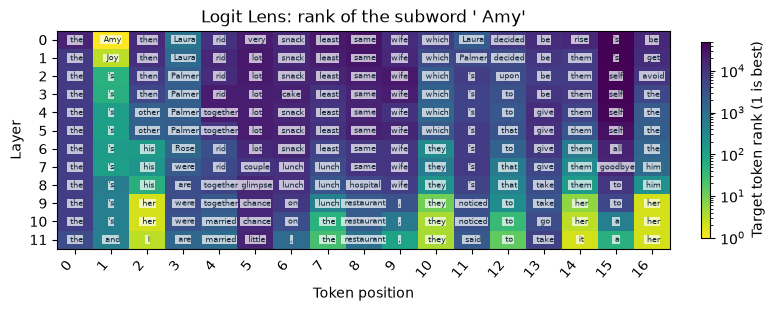

In [3]:
layers = sorted(probe.describe()["methods"]["lens.logit"]["sites"])
result = probe.lens.logit(layers=layers, tokens="text").run(inputs)
print("logits [layers, packed positions, vocabulary]:", result.tensors["logits"].shape)
print("[batch, expanded-token position]:", result.tensors["positions"])
result.save(OUT / "logit-result")
ax = plot_lens_heatmap(result, target_token_id=answer_id, tokenizer=tokenizer,
                       title="Logit Lens: rank of the subword ' Amy'")
ax.figure.savefig(OUT / "logit.png", dpi=160, bbox_inches="tight")
plt.show()


## 3. Fit Tuned Lens, validate and restore it

The frozen model supplies the teacher distribution. The initial checkpoint is included in best-checkpoint selection; lower KL is closer teacher agreement, not evidence of a more truthful model.

{"method": "tuned_lens", "epoch": 1, "train_kl": 5.0734596782260475, "train_positions": 36, "optimizer_steps": 3, "validation": {"kl": 2.8792255255911083, "top1_agreement": 0.2222222222222222, "positions": 18}, "elapsed_seconds": 0.7346553390088957, "best_validation_kl": 2.8792255255911083}


{"method": "tuned_lens", "epoch": 2, "train_kl": 2.506798426310221, "train_positions": 36, "optimizer_steps": 3, "validation": {"kl": 2.32266992992825, "top1_agreement": 0.2777777777777778, "positions": 18}, "elapsed_seconds": 1.4232278740091715, "best_validation_kl": 2.32266992992825}


{"method": "tuned_lens", "epoch": 1, "train_kl": 2.568816661834717, "train_positions": 36, "optimizer_steps": 3, "validation": {"kl": 1.5372396839989557, "top1_agreement": 0.5, "positions": 18}, "elapsed_seconds": 0.6865504930028692, "best_validation_kl": 1.5372396839989557}


{"method": "tuned_lens", "epoch": 2, "train_kl": 1.7548730108473036, "train_positions": 36, "optimizer_steps": 3, "validation": {"kl": 1.5091209411621094, "top1_agreement": 0.5, "positions": 18}, "elapsed_seconds": 1.3677379779983312, "best_validation_kl": 1.5091209411621094}


{"method": "tuned_lens", "epoch": 1, "train_kl": 0.1043654327744979, "train_positions": 36, "optimizer_steps": 3, "validation": {"kl": 0.23573015133539835, "top1_agreement": 0.7222222222222222, "positions": 18}, "elapsed_seconds": 0.6753269799810369, "best_validation_kl": -1.524992083230043e-09}


{"method": "tuned_lens", "epoch": 2, "train_kl": 0.5368770692083571, "train_positions": 36, "optimizer_steps": 3, "validation": {"kl": 0.21954421202341715, "top1_agreement": 0.6666666666666666, "positions": 18}, "elapsed_seconds": 1.3662766689958517, "best_validation_kl": -1.524992083230043e-09}


0 best held-out KL: 2.32266992992825
6 best held-out KL: 1.5091209411621094
11 best held-out KL: -1.524992083230043e-09
logits: torch.Size([3, 17, 50257])


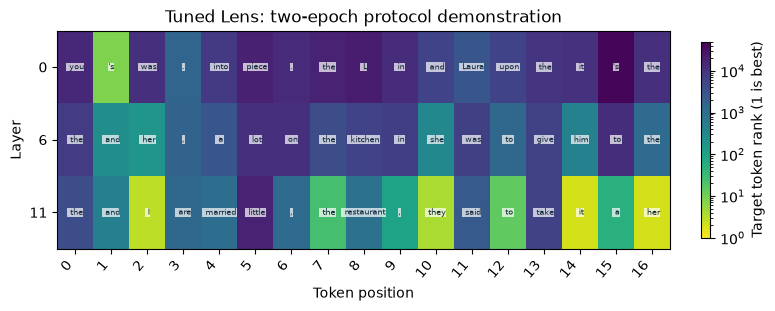

In [4]:
layers = [0, model.config.n_layer // 2, model.config.n_layer - 1]
lens = probe.lens.tuned(layers=layers, tokens="text", binding=binding)
lens.fit_batches(train_inputs, validation_inputs, OUT / "tuned-artifact",
                 batch_size=16, epochs=2, lr=1e-3, patience=2, seed=0,
                 resume=False)
for layer, history in lens.training_history.items():
    print(layer, "best held-out KL:", history["best_validation_kl"])
result = lens.run(inputs)
print("logits:", result.tensors["logits"].shape)
ax = plot_lens_heatmap(result, target_token_id=answer_id, tokenizer=tokenizer,
                       title="Tuned Lens: two-epoch protocol demonstration")
ax.figure.savefig(OUT / "tuned.png", dpi=160, bbox_inches="tight")
plt.show()
# Artifact restoration uses the same checkpoint/tokenizer/calibration identities.
restored = probe.lens.tuned(layers=layers, tokens="text", binding=binding).load(OUT / "tuned-artifact")


## 4. Fit per-head Attention Lens decoders (explicit opt-in)

Change the switch to `True` only after checking GPU/RAM capacity. This trains one dense layer from the native unembedding. The entire training and plotting code is visible below; it is not a call to hidden demo helpers.

In [5]:
RUN_DENSE_ATTENTION_TRAINING = False
if RUN_DENSE_ATTENTION_TRAINING:
    # GPT-2: 12 * 768 * 50,257 = 463,168,512 decoder weights per layer.
    # Adam/gradients need several times the weight memory; prefer a GPU with ample RAM.
    layer = int(os.environ.get("VLM_PROBING_ATTENTION_LAYER", "7"))
    assert layer in probe.describe()["methods"]["lens.attention"]["sites"]
    lens = probe.lens.attention(layers=[layer], tokens="last_prompt", binding=binding)
    head = model.get_output_embeddings()
    lens.fit_batches(train_inputs, validation_inputs, OUT / "attention-artifact",
                     initial_unembedding=head.weight, initial_bias=getattr(head, "bias", None),
                     batch_size=4, epochs=2, lr=1e-4, patience=2, seed=0,
                     resume=False)
    result = lens.run(inputs)
    print("head logits [layer, packed position, head, vocabulary]:", result.tensors["head_logits"].shape)
    print("summed logits:", result.tensors["logits"].shape)
    # Put the measured heads on rows; this is not a layer axis.
    head_logits = result.tensors["head_logits"][0].permute(1, 0, 2)
    fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
    ax = plot_lens_heatmap(head_logits, ax=ax, target_token_id=answer_id,
                           layer_labels=[f"Head {i}" for i in range(head_logits.shape[0])],
                           token_labels=["Final prompt position"], tokenizer=tokenizer,
                           title=f"Attention Lens: GPT-2 layer {layer}")
    ax.set_ylabel("Attention head")
    ax.tick_params(axis="y", labelsize=9)
    ax.tick_params(axis="x", labelrotation=0)
    ax.set_xlabel("")
    ax.figure.savefig(OUT / "attention.png", dpi=160, bbox_inches="tight")
    plt.show()
    print("best held-out KL:", lens.training_history[layer]["best_validation_kl"])
    restored = probe.lens.attention(layers=[layer], binding=binding).load(OUT / "attention-artifact")
else:
    print("Skipped: dense Attention Lens training. Set the switch above after checking memory.")

Skipped: dense Attention Lens training. Set the switch above after checking memory.


## 5. Estimate a Jacobian Lens (explicit opt-in)

This computes exact derivative transport on two independent calibration prompts. It does not train a classifier. Grouped VJPs reduce call overhead, not the number of derivatives.

In [6]:
RUN_EXACT_JACOBIAN_CALIBRATION = False
if RUN_EXACT_JACOBIAN_CALIBRATION:
    from vlmprobe.training import fit_jacobian_lenses

    layers = [model.config.n_layer // 2, model.config.n_layer - 1]
    # Exact VJPs still scale with hidden width: dim_batch changes grouping, not accuracy.
    lens, calibration = fit_jacobian_lenses(
        probe, train_inputs[:2], layers=layers, binding=binding,
        directory=OUT / "jacobian-artifact", dim_batch=32,
        skip_first=0, exclude_last=False, tokens="text", resume=False,
    )
    result = lens.run(inputs)
    print("calibrated prompts:", calibration["prompts"])
    print("transported / logits:", result.tensors["transported"].shape, result.tensors["logits"].shape)
    ax = plot_lens_heatmap(result, target_token_id=answer_id, tokenizer=tokenizer,
                           title="Jacobian Lens: two-prompt calibration demonstration")
    ax.figure.savefig(OUT / "jacobian.png", dpi=160, bbox_inches="tight")
    plt.show()
    restored = probe.lens.jacobian(layers=layers, tokens="text", binding=binding).load(OUT / "jacobian-artifact")
else:
    print("Skipped: exact Jacobian calibration. Set the switch above to compute it.")

Skipped: exact Jacobian calibration. Set the switch above to compute it.


## 6. Move a source residual into a target copy prompt

Patchscope performs an actual residual replacement. The result is teacher-forced target logits; this example does not pretend it generated an explanation.

teacher-forced logits [source layer, batch, target position, vocabulary]: torch.Size([3, 1, 11, 50257])
0 top next subword: ':'
6 top next subword: ','
11 top next subword: '.'


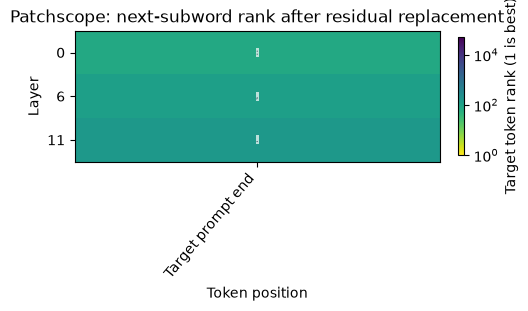

In [7]:
source_text = "The capital of France is Paris"
target_text = "Apple: Apple\nOrange: Orange\nBanana:"
source_inputs, target_inputs = prepare(source_text), prepare(target_text)
source_position = source_inputs.kwargs["input_ids"].shape[1] - 1
target_position = target_inputs.kwargs["input_ids"].shape[1] - 1
layers = [0, model.config.n_layer // 2, model.config.n_layer - 1]
scope = probe.lens.patchscope(layers=layers, source_position=source_position,
                              target_layer=0, target_position=target_position)
result = scope.run(source_inputs, target_inputs=target_inputs)
print("teacher-forced logits [source layer, batch, target position, vocabulary]:", result.tensors["logits"].shape)
# Last target-position logits measure one next-token readout, not generated text.
paris_ids = tokenizer.encode(" Paris", add_special_tokens=False)
assert len(paris_ids) == 1
logits = result.tensors["logits"][:, 0, -1:, :]
for layer, row in zip(layers, logits[:, 0]):
    print(layer, "top next subword:", repr(tokenizer.decode([int(row.argmax())])))
ax = plot_lens_heatmap(logits, target_token_id=paris_ids[0], layer_labels=layers,
                       token_labels=["Target prompt end"], tokenizer=tokenizer,
                       title="Patchscope: next-subword rank after residual replacement")
ax.figure.savefig(OUT / "patchscope.png", dpi=160, bbox_inches="tight")
plt.show()


## Move to a different checkpoint

Use the corresponding [model guide](../docs/models/README.md) to load the model,
prepare its native text/image inputs and inspect `probe.describe()`. The factory
calls above stay the same for supported layers. Fitted artifacts never transfer
silently between checkpoints. Qwen3.5 supports residual lenses on every decoder
block, but head decoders only on standard-attention blocks.

[Logit Lens](../docs/methods/logit_lens.md) · [Tuned Lens](../docs/methods/tuned_lens.md) ·
[Attention Lens](../docs/methods/attention_lens.md) · [Jacobian Lens](../docs/methods/jacobian_lens.md) ·
[Patchscope](../docs/methods/patchscope.md) · [Full calibration protocol](../docs/TRAINING.md).
